## Run trial from_nemo W_correction 

In [1]:
num_particles = 100
run_time_days = 20
time_step_minutes = 10
out_put_step_hours = 6

#initial position
# -50.0 -49.08333206176758 -0.08333330601453781 1.1665860414505005
# -49.75, -48.33,-0.17,1.33
# lon0 = -49.916
# lon1 = -49.083
# lat0 = 1.166
# lat1 = -0.0833

depth_min = 0 #todo: figure near-surface depths 
depth_max = 7

offset = 1
ref_date = "1993-01-01"
#reproducibility
rdm_seed = 12
#paths
pathUVW= '/work/bk1450/b383184/Amazon/Mercator/data/variables_c/UVW'
pathTS = "/work/bk1450/b383184/Amazon/Mercator/data/variables_c/tracers"
Hgr = "/work/bk1450/b383184/Amazon/Mercator/data/Hgr_cmesh.nc"
Zgr = "/work/bk1450/b383184/Amazon/Mercator/data/Zgr_cmesh2.nc"

In [2]:
# --- release polygon: green band (from release_polygon_map.ipynb) ---
#   A  Amazon coast  - start of the old release line
#   B  Para coast    - old line prolonged SE until it strikes the Para bank
#   B' seaward corner off B  (pushed NE, not perpendicular: the Maranhao coast
#                             bends east, so a perpendicular corner runs aground)
#   A' seaward corner off A  (0.8 deg perpendicular)
vertices = {
    "A":  (-49.916,  1.166),   # Amazon coast  - start of release line
    "B":  (-49, -0.16),
    "B'": (-48.3,-0.2),
    "C":  (-48.5,-0.75),
    "C'": (-48.45,-1.05),
    "D":  (-48.12, -0.73 ),   # Para coast    - line prolonged SE to Para bank
    "D'": (-47.8,   -0.6  ),   # seaward corner off B (pushed NE)
    "A'": (-49.250,  1.610),   # seaward corner off A (0.8 deg perpendicular)
}

# build the closed ring (repeat the first point at the end)
_pts = list(vertices.values())
green_lons = [p[0] for p in _pts] + [_pts[0][0]]
green_lats = [p[1] for p in _pts] + [_pts[0][1]]


In [3]:
import numpy as np

In [4]:
out_path = f'tracks_{rdm_seed}/' #path to store the particle zarr

start_time = np.datetime64(ref_date) + np.timedelta64(offset, "D")
start_time

np.datetime64('1993-01-02')

## Particles from the ARP to the Atlantic

In [5]:
from parcels import ParticleSet
from parcels import JITParticle
# from parcels import ScipyParticle
from parcels import AdvectionRK4_3D
from parcels import AdvectionRK4
from parcels import Variable
from datetime import timedelta
import numpy as np
from parcels import FieldSet
from glob import glob

In [6]:
np.random.seed(rdm_seed)

In [7]:
ufiles = f"{pathUVW}/U_1993-01c.nc"
vfiles = f"{pathUVW}/V_1993-01c.nc"
wfiles = f"{pathUVW}/W_1993-01fc.nc"


In [8]:
## define the fieldset
filenames = {
    "U": {
        "data":ufiles,
        "lon": Hgr,
        "lat": Hgr,
        "depth": wfiles,
    },
    
    "V": {
        "data": vfiles,
        "lon": Hgr,
        "lat": Hgr,
        "depth": wfiles,
    },
    
    "W": {
        "data": wfiles,
        "lon": Hgr,
        "lat": Hgr,
        "depth": wfiles,
    },
}

variables = {
    "U": "vozocrtx",
    "V": "vomecrty",
    "W": "vovecrtz",
}

interp_method = {
    "U":"cgrid_velocity",
    "V":"cgrid_velocity",
    "W":"cgrid_velocity",
}


dimensions = {
    "U": {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"},
    "V": {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"},
    "W": {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"},
}


## now the fieldset
fieldset = FieldSet.from_nemo(
    filenames, 
    variables, 
    dimensions,
    # interp_method = interp_method,
    # tracer_interp_method="cgrid_tracer",
    deferred_load=True,
    allow_time_extrapolation = False,
    # gridindexingtype = "nemo",
)


In [9]:
# --- carve the land out of the release band, using the model's own mask ---

#
# mbathy (Zgr) is the number of wet levels at each T point, i.e. NEMO's own land
# mask. Keep a T cell only if its column holds depth_max, then intersect the
# band with the union of those cells. The result follows the model coastline,
# not the Natural Earth one, which is what actually decides where particles sit.
import xarray as xr
from shapely.geometry import Polygon
from shapely.ops import unary_union

_h  = xr.open_dataset(Hgr)
_z  = xr.open_dataset(Zgr)
glamf = _h.glamf.isel(t=0).values          # f points = cell corners
gphif = _h.gphif.isel(t=0).values
mbathy = _z.mbathy.isel(t=0).values        # wet levels per T column (0 = land)
depthw = xr.open_dataset(wfiles).depthw.values

kmin = int(np.searchsorted(depthw, depth_max))   # levels needed to hold depth_max
band = Polygon(zip(green_lons[:-1], green_lats[:-1]))
bl, bs, br, bn = band.bounds

# index window around the band, so we only walk a few hundred cells
_in = (glamf >= bl-0.2) & (glamf <= br+0.2) & (gphif >= bs-0.2) & (gphif <= bn+0.2)
_j, _i = np.where(_in)
j0, j1, i0, i1 = _j.min(), _j.max(), _i.min(), _i.max()

# NEMO/parcels convention: T cell (j,i) has corners f(j-1,i-1)..f(j,i)
wet_cells = []
for j in range(j0+1, j1+1):
    for i in range(i0+1, i1+1):
        if mbathy[j, i] < kmin:
            continue
        q = Polygon([(glamf[j-1, i-1], gphif[j-1, i-1]), (glamf[j-1, i], gphif[j-1, i]),
                     (glamf[j,   i  ], gphif[j,   i  ]), (glamf[j,   i-1], gphif[j,   i-1])])
        if q.intersects(band):
            wet_cells.append(q)

wet_band = band.intersection(unary_union(wet_cells))
if wet_band.geom_type == 'MultiPolygon':                 # keep the main lobe
    wet_band = max(wet_band.geoms, key=lambda g: g.area)

wet_lons, wet_lats = np.array(wet_band.exterior.coords).T
print(f"band {band.area:.3f} deg^2 -> wet band {wet_band.area:.3f} deg^2 "
      f"({100*wet_band.area/band.area:.1f}% kept, {len(wet_lons)-1} vertices)")


band 1.778 deg^2 -> wet band 1.775 deg^2 (99.8% kept, 20 vertices)


In [10]:
# uniform seeding inside the wet band (rejection sampling in its bounding box)
from shapely.geometry import Point
from shapely.prepared import prep

_wb = prep(wet_band)
wl, ws, wr, wn = wet_band.bounds

start_lon = np.empty(num_particles)
start_lat = np.empty(num_particles)
n = 0
while n < num_particles:
    batch = max(num_particles - n, 1) * 3          # over-sample, most fall outside
    x = np.random.uniform(wl, wr, size=batch)
    y = np.random.uniform(ws, wn, size=batch)
    keep = np.fromiter((_wb.contains(Point(a, b)) for a, b in zip(x, y)),
                       dtype=bool, count=batch)
    x, y = x[keep], y[keep]
    take = min(len(x), num_particles - n)
    start_lon[n:n+take] = x[:take]
    start_lat[n:n+take] = y[:take]
    n += take

start_depth = np.random.uniform(depth_min, depth_max, size=num_particles)
start_times = np.datetime64(start_time)


In [11]:
# sanity check: ask parcels itself whether any seed landed on a dry cell.
# Land velocities are zeroed on load, so an exactly-zero UVW means a dry cell.
fieldset.computeTimeChunk(fieldset.U.grid.time[0], 1)
_t = fieldset.U.grid.time[0]
_dry = sum(fieldset.UVW[_t, d, la, lo] == (0.0, 0.0, 0.0)
           for lo, la, d in zip(start_lon, start_lat, start_depth))
print(f"{_dry}/{num_particles} particles seeded on land")
assert _dry == 0, "some particles are on land - widen kmin or check the mask"


0/100 particles seeded on land


In [12]:
pset = ParticleSet(
    fieldset=fieldset,
    lon = start_lon,
    lat = start_lat,
    depth=start_depth,
    time=start_times
) 

out_fn = f'Parcels_run_{rdm_seed}_{start_time}.zarr'

output_file = pset.ParticleFile(
    name=out_path+out_fn,
    outputdt=timedelta(hours=out_put_step_hours),
    chunks = (num_particles,int(run_time_days*24/out_put_step_hours/4))
)

In [13]:
##check the error
def CheckError(particle, fieldset, time):
    if particle.state >= 50:  # This captures all Errors
        particle.delete()

In [14]:
## Execute particles
pset.execute(
    [AdvectionRK4_3D,CheckError],
    runtime=timedelta(days=run_time_days),
    dt=timedelta(minutes=time_step_minutes),
    output_file= output_file
)

INFO: Output files are stored in tracks_12/Parcels_run_12_1993-01-02.zarr.
100%|██████████| 1728000.0/1728000.0 [02:45<00:00, 10441.98it/s]


## Plotting

In [15]:
import xarray as xr

In [16]:
out_path = f'tracks_{rdm_seed}/'
# out_fn = 'Parcels_run_692' 

ds_traj = xr.open_zarr(out_path+out_fn)
# ds_traj = ds_traj.compute()
ds_traj = ds_traj.compute()
ds_traj

<xarray.Dataset> Size: 257kB
Dimensions:     (trajectory: 100, obs: 80)
Coordinates:
  * obs         (obs) int32 320B 0 1 2 3 4 5 6 7 8 ... 72 73 74 75 76 77 78 79
  * trajectory  (trajectory) int64 800B 0 1 2 3 4 5 6 7 ... 93 94 95 96 97 98 99
Data variables:
    lat         (trajectory, obs) float64 64kB -0.4067 -0.3916 ... 0.1844 0.1941
    lon         (trajectory, obs) float64 64kB -48.35 -48.35 ... -49.36 -49.38
    time        (trajectory, obs) datetime64[ns] 64kB 1993-01-02 ... 1993-01-...
    z           (trajectory, obs) float64 64kB 1.845 1.902 1.957 ... 2.325 2.324
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        JITParticleAdvectionRK4_3DCheckError
    parcels_mesh:           spherical
    parcels_version:        3.1.2

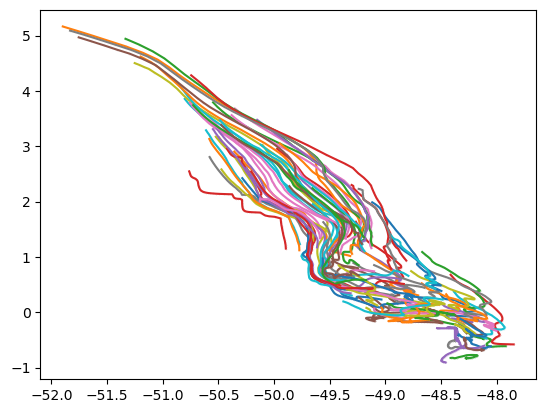

In [17]:
import matplotlib.pyplot as plt
for ii in range(100):
    plt.plot(ds_traj.isel(trajectory=ii).lon.data, ds_traj.isel(trajectory=ii).lat.data,marker='.',markersize=0.1)


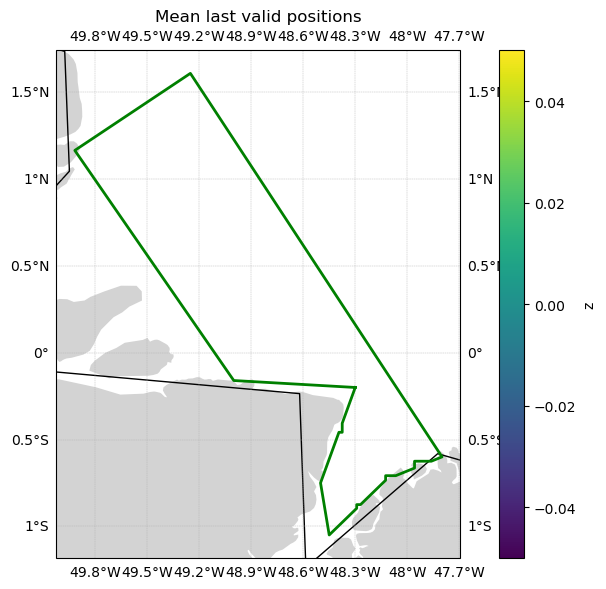

In [18]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

last_valid = ds_traj.lat.notnull().astype(int).diff('obs', label='lower') == -1
ends = ds_traj.where(last_valid).mean('obs').compute()

fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.coastlines(resolution='110m')
ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.gridlines(draw_labels=True, linestyle='--', linewidth=0.3)

ends.plot.scatter(
    x='lon',
    y='lat',
    hue='z' if 'z' in ends else None,
    cmap='viridis',
    s=30,
    ax=ax,
    transform=ccrs.PlateCarree()
)

ax.plot(wet_lons, wet_lats, color='green', lw=2)

plt.title('Mean last valid positions')
plt.tight_layout()
plt.show()

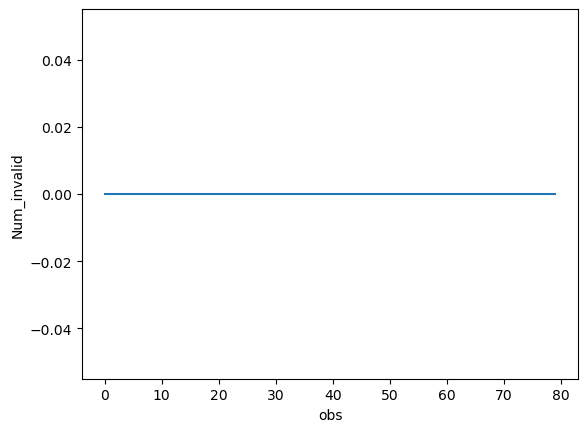

In [19]:
import matplotlib.pyplot as plt
ds_traj.lat.isnull().sum('trajectory').rename('Num_invalid').plot()
plt.show()